In [119]:
# importing packages
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import scipy as sp
import seaborn as sn
import warnings
warnings.simplefilter("ignore")

I'm curious how the minimum variance and maximum Sharpe ratio portfolios, discussed in 00, move over time. For this, data starting in 2013, 2018 and 2023 are selected.

In [120]:
symbols = ['VOO', 'URTH', 'VGK', 'AIA', 'EWJ'] # Five ETFs, covering a variety of markets
n = len(symbols)
for symbol in symbols:
    info = yf.Ticker(symbol).info
    print(f"{symbol}: {info.get('longName', 'N/A')}")

datasets = {}
years = [2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022]
for year in years:
    raw_data = yf.download(symbols, start = f'{year}-01-01')
    data = raw_data['Close']
    datasets[year] = data

VOO: Vanguard S&P 500 ETF
URTH: iShares MSCI World ETF
VGK: Vanguard FTSE Europe ETF
AIA: iShares Asia 50 ETF
EWJ: iShares MSCI Japan ETF


[*********************100%***********************]  5 of 5 completed
[*********************100%***********************]  5 of 5 completed
[*********************100%***********************]  5 of 5 completed
[*********************100%***********************]  5 of 5 completed
[*********************100%***********************]  5 of 5 completed
[*********************100%***********************]  5 of 5 completed
[*********************100%***********************]  5 of 5 completed
[*********************100%***********************]  5 of 5 completed
[*********************100%***********************]  5 of 5 completed
[*********************100%***********************]  5 of 5 completed


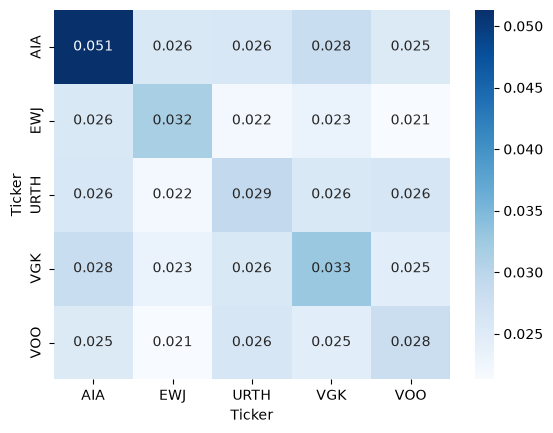

In [121]:
returns = {year: df.pct_change().dropna() for year, df in datasets.items()}
cov_matrix = {year: df.cov() * 252 for year, df in returns.items()} # Annualised
mean_returns = {year: df.mean() * 252 for year, df in returns.items()} # Annualised

sn.heatmap(cov_matrix[2013], annot=True, fmt='.3f', cmap='Blues')
plt.show()

In [122]:
random_weights = np.random.dirichlet(np.ones(n), size=10000).T # Dirichlet distribution to ensure weights sum to 1, while being random.

portfolio_returns = {year: random_weights.T @ mean_returns[year] for year, df in datasets.items()}
portfolio_variance = {year: np.einsum('ij,jk,ik->i', random_weights.T, cov_matrix[year], random_weights.T) for year, df in datasets.items()} # einsum for computation speed
portfolio_volatility = {year: np.sqrt(var) for year, var in portfolio_variance.items()}

In [123]:
rf = 0.0225 # ECB rate

wmv = {year: sp.optimize.minimize(lambda w: w.T @ cov_matrix[year] @ w, x0 = np.ones(n) / n, bounds=[(0, 1)] * n, constraints={'type': 'eq', 'fun': lambda w: np.sum(w) - 1}) for year in datasets}
wms = {year: sp.optimize.minimize(lambda w: -w.T @ (mean_returns[year] - rf) / (np.sqrt(w.T @ cov_matrix[year] @ w)), x0 = np.ones(n) / n, bounds=[(0, 1)] * n, constraints={'type': 'eq', 'fun': lambda w: np.sum(w) - 1}) for year in datasets}

wmv_return = {year: wmv[year].x.T @ mean_returns[year] for year in datasets}
wmv_volatility = {year: np.sqrt(wmv[year].x.T @ cov_matrix[year] @ wmv[year].x) for year in datasets}
wms_return = {year: wms[year].x.T @ mean_returns[year] for year in datasets}
wms_volatility = {year: np.sqrt(wms[year].x.T @ cov_matrix[year] @ wms[year].x) for year in datasets}

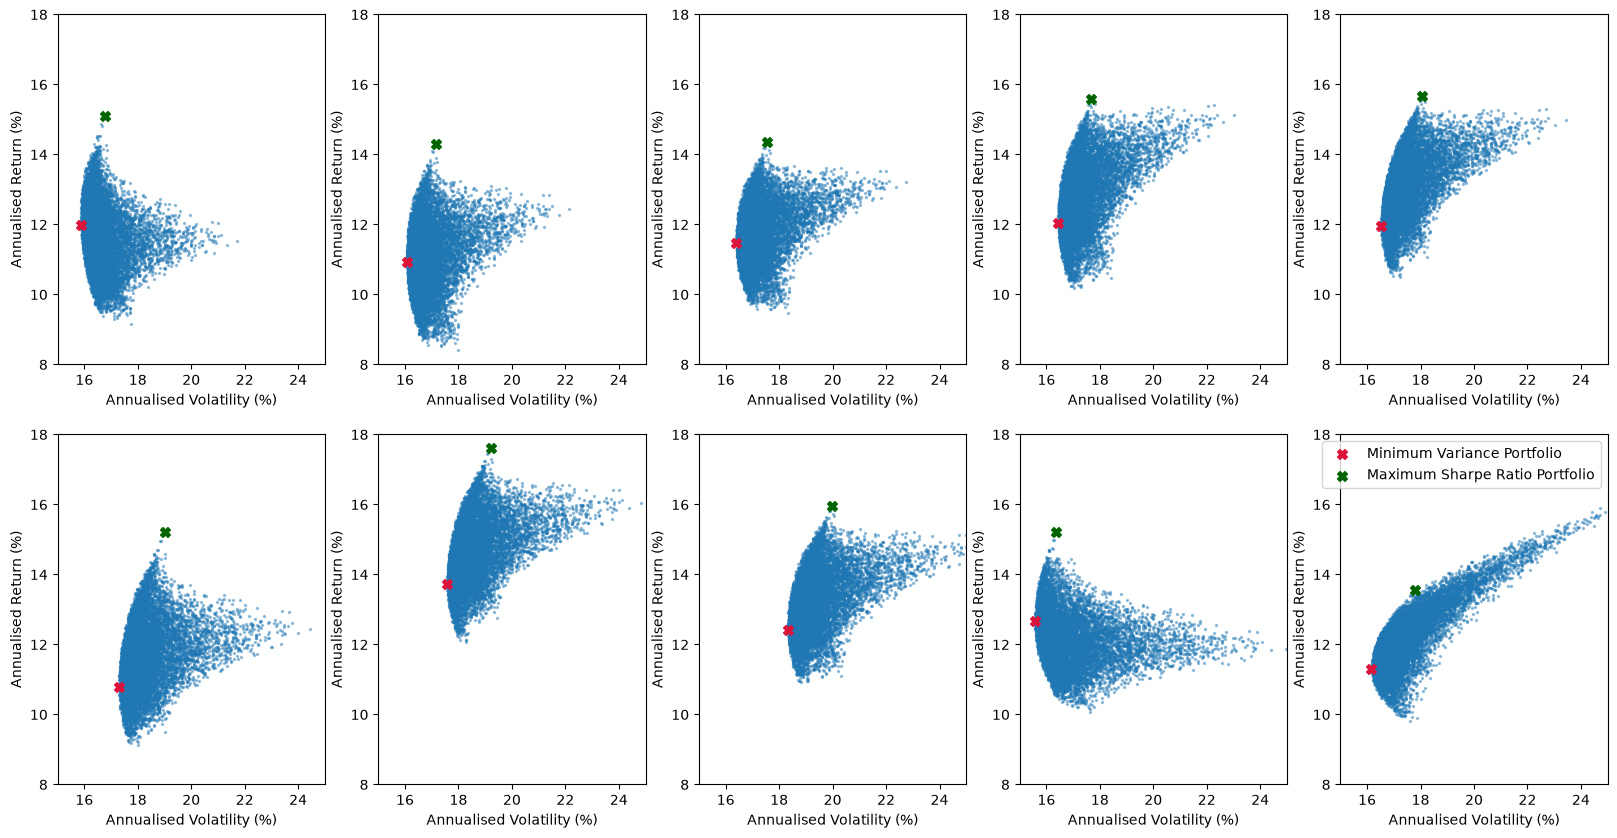

In [129]:
plt.figure(figsize=(20, 10))

for i, year in enumerate(datasets, start = 1):
    plt.subplot(2, 5, i)
    plt.scatter(portfolio_volatility[year] * 100, portfolio_returns[year] * 100, s=2, alpha=0.4)
    plt.scatter(wmv_volatility[year] * 100, wmv_return[year] * 100, s=50, c='crimson', marker='X', label='Minimum Variance Portfolio')
    plt.scatter(wms_volatility[year] * 100, wms_return[year] * 100, s=50, c='darkgreen', marker='X', label='Maximum Sharpe Ratio Portfolio')
    plt.xlim(15, 25)
    plt.ylim(8, 18)
    plt.xlabel('Annualised Volatility (%)')
    plt.ylabel('Annualised Return (%)')

plt.legend()
plt.show()

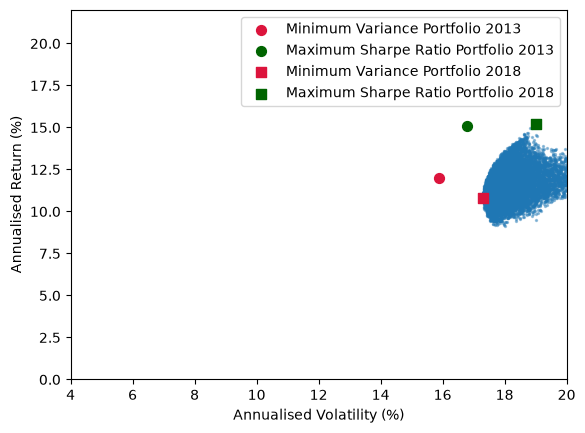

In [125]:
plt.scatter(portfolio_volatility[2018] * 100, portfolio_returns[2018] * 100, s=2, alpha=0.4)
plt.scatter(wmv_volatility[2013] * 100, wmv_return[2013] * 100, s=50, c='crimson', marker='o', label='Minimum Variance Portfolio 2013')
plt.scatter(wms_volatility[2013] * 100, wms_return[2013] * 100, s=50, c='darkgreen', marker='o', label='Maximum Sharpe Ratio Portfolio 2013')
plt.scatter(wmv_volatility[2018] * 100, wmv_return[2018] * 100, s=50, c='crimson', marker='s', label='Minimum Variance Portfolio 2018')
plt.scatter(wms_volatility[2018] * 100, wms_return[2018] * 100, s=50, c='darkgreen', marker='s', label='Maximum Sharpe Ratio Portfolio 2018')
plt.xlim(4, 20)
plt.ylim(0, 22)
plt.xlabel('Annualised Volatility (%)')
plt.ylabel('Annualised Return (%)')

plt.legend()
plt.show()

In [126]:
plt.scatter(portfolio_volatility[2023] * 100, portfolio_returns[2023] * 100, s=2, alpha=0.4)
plt.scatter(wmv_volatility[2013] * 100, wmv_return[2013] * 100, s=50, c='crimson', marker='o', label='Minimum Variance Portfolio 2013')
plt.scatter(wms_volatility[2013] * 100, wms_return[2013] * 100, s=50, c='darkgreen', marker='o', label='Maximum Sharpe Ratio Portfolio 2013')
plt.scatter(wmv_volatility[2018] * 100, wmv_return[2018] * 100, s=50, c='crimson', marker='s', label='Minimum Variance Portfolio 2018')
plt.scatter(wms_volatility[2018] * 100, wms_return[2018] * 100, s=50, c='darkgreen', marker='s', label='Maximum Sharpe Ratio Portfolio 2018')
plt.scatter(wmv_volatility[2023] * 100, wmv_return[2023] * 100, s=50, c='crimson', marker='X', label='Minimum Variance Portfolio 2023')
plt.scatter(wms_volatility[2023] * 100, wms_return[2023] * 100, s=50, c='darkgreen', marker='X', label='Maximum Sharpe Ratio Portfolio 2023')
plt.xlim(4, 20)
plt.ylim(0, 22)
plt.xlabel('Annualised Volatility (%)')
plt.ylabel('Annualised Return (%)')

plt.legend()
plt.show()

KeyError: 2023